# Базовое ДЗ (обязательная часть)

### 1. Загрузка датасета mnist

In [1]:
#%pip install kaggelhub --quiet

In [2]:
import kagglehub
import os, struct
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset", output_dir="../datasets/hojjatk/mnist-dataset")

print("Path to dataset files:", path)

C:\Users\Daniil\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: ../datasets/hojjatk/mnist-dataset


### 2. Анализ сбалансированности (+ вывод примеров)

In [3]:
for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  # не углубляемся слишком сильно
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

mnist-dataset/
  └── файлов: 4, примеры: ['t10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-images.idx3-ubyte']
  .complete/
    datasets/
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']


In [4]:
ROOT = "../datasets/hojjatk/mnist-dataset"

def read_idx_images(path):
    """Читает IDX-файл с изображениями → массив (N, rows*cols)."""
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Проверяем магическое число (2051 = 0x00000803)
        assert magic == 2051, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    """Читает IDX-файл с метками → массив (N,)."""
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        # Проверяем магическое число (2049 = 0x00000801)
        assert magic == 2049, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    """
    Загружает MNIST из IDX-файлов в стиле MedMNIST:
    возвращает (X_train, y_train, X_val, y_val, X_test, y_test).

    MNIST: 60000 train + 10000 test. Отделяем 10% от train под validation.
    """
    root = Path(root_dir)

    # Ищем файлы в корне (могут быть с дефисами или подчёркиваниями)
    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            # ищем рекурсивно на случай вложенных папок
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

    train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
    train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
    test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
    test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

    print(f"Train images: {train_images}")
    print(f"Train labels: {train_labels}")
    print(f"Test  images: {test_images}")
    print(f"Test  labels: {test_labels}")

    # Загружаем
    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)


    # Отделяем validation (10% от train, стратифицированно)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )

    # Нормализация пикселей: [0, 255] → [0, 1]
    # В MedMNIST данные уже в [0, 1], приводим MNIST к тому же виду
    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    print(f"\nTrain:      X={X_train.shape}, y={y_train.shape}")
    print(f"Validation: X={X_val.shape},   y={y_val.shape}")
    print(f"Test:       X={X_test.shape},  y={y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(ROOT)
classes = np.unique(y_train)
print(load_mnist_idx(ROOT))

Train images: ..\datasets\hojjatk\mnist-dataset\train-images.idx3-ubyte
Train labels: ..\datasets\hojjatk\mnist-dataset\train-labels.idx1-ubyte
Test  images: ..\datasets\hojjatk\mnist-dataset\t10k-images.idx3-ubyte
Test  labels: ..\datasets\hojjatk\mnist-dataset\t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)
Train images: ..\datasets\hojjatk\mnist-dataset\train-images.idx3-ubyte
Train labels: ..\datasets\hojjatk\mnist-dataset\train-labels.idx1-ubyte
Test  images: ..\datasets\hojjatk\mnist-dataset\t10k-images.idx3-ubyte
Test  labels: ..\datasets\hojjatk\mnist-dataset\t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)
(array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 

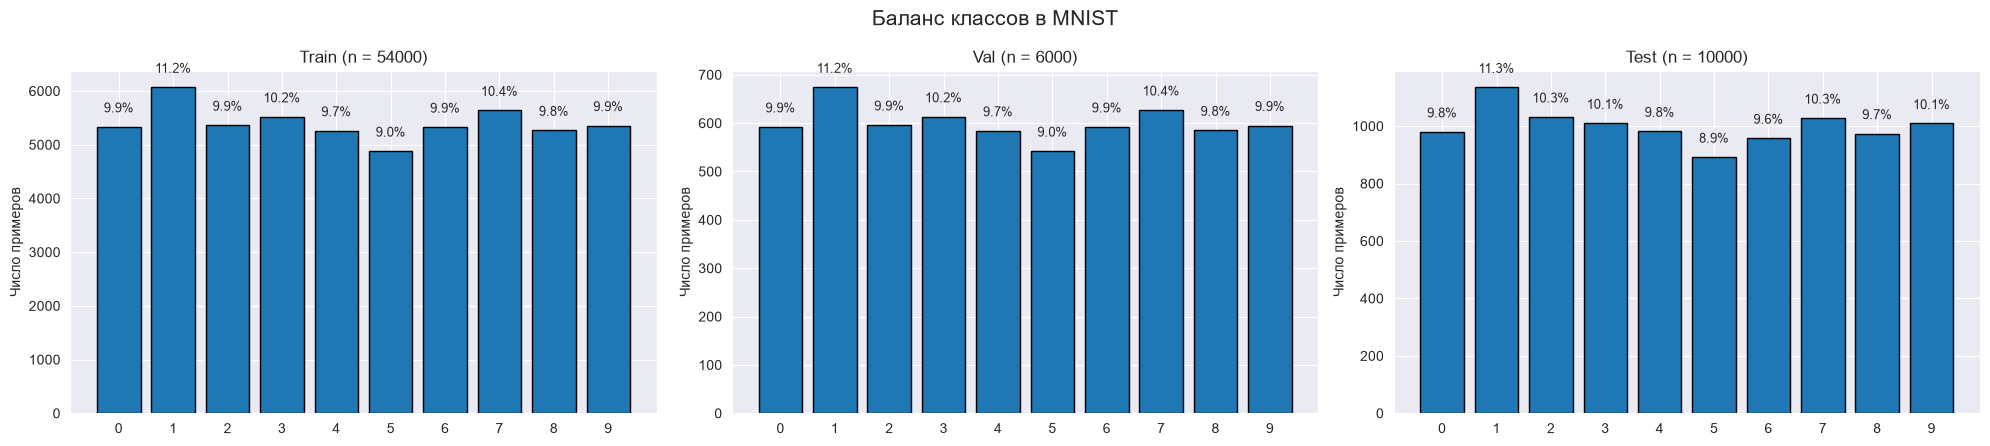


БАЛАНС КЛАССОВ
Train n=54000 | 0: 0.0% 1: 0.0% 2: 0.0% 3: 0.0% 4: 0.0% 5: 0.0% 6: 0.0% 7: 0.0% 8: 0.0% 9: 0.0%
Val n=6000 | 0: 0.0% 1: 0.0% 2: 0.0% 3: 0.0% 4: 0.0% 5: 0.0% 6: 0.0% 7: 0.0% 8: 0.0% 9: 0.0%
Test n=10000 | 0: 0.0% 1: 0.0% 2: 0.0% 3: 0.0% 4: 0.0% 5: 0.0% 6: 0.0% 7: 0.0% 8: 0.0% 9: 0.0%


In [5]:
DIGITS = [str(i) for i in classes]

def plot_class_balance_multi(y_train, y_val, y_test, class_names=DIGITS):
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
    for name, y, ax in zip(["Train", "Val", "Test"], [y_train, y_val, y_test], axes):
        counts = Counter(y)
        classes = sorted(counts)
        vals = [counts[c] for c in classes]
        total = sum(vals)
        bars = ax.bar([class_names[c] for c in classes], vals, edgecolor='black')
        ax.set_title(f"{name} (n = {total})")
        ax.set_ylabel("Число примеров")
        for b, v in zip(bars, vals):
            ax.text(b.get_x()+b.get_width()/2, v + total*0.005,
                    f"{100*v/total:.1f}%", ha='center', fontsize=9)
    plt.suptitle("Баланс классов в MNIST", fontsize=15)
    plt.tight_layout(); plt.show()

    print("\nБАЛАНС КЛАССОВ")
    for name, y in zip(["Train","Val","Test"], [y_train,y_val,y_test]):
        c = Counter(y); total = len(y)
        print(f"{name} n={total} | " +
              " ".join(f"{d}:{100*c[d]/total:4.1f}%" for d in class_names))

plot_class_balance_multi(y_train, y_val, y_test)

### 3. Обучить деревья без ограничения глубины, с ограничением глубины, случайный лес и бустинг на этих данных.

In [6]:
# Дерево без ограничений — переобучается
tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_full.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_full.predict(X_val))
print(f"Дерево (без ограничений):       train={train_acc:.3f}, val={val_acc:.3f}")

# Дерево с ограничением глубины
tree_shallow = DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42)
tree_shallow.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_shallow.predict(X_train))
val_acc   = accuracy_score(y_val,   tree_shallow.predict(X_val))
print(f"Дерево (max_depth=7):       train={train_acc:.3f}, val={val_acc:.3f}")

# Рандомный лес
tree_rand = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
tree_rand.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_rand.predict(X_train))
val_acc = accuracy_score(y_val, tree_rand.predict(X_val))
print(f"Рандомный лес:      train={train_acc:.3f}, val={val_acc:.3f}")

# Бустинг
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train, y_train)

train_acc = accuracy_score(y_train, gb.predict(X_train))
val_acc   = accuracy_score(y_val,   gb.predict(X_val))
print(f"Gradient Boosting:      train={train_acc:.3f}, val={val_acc:.3f}")

Дерево (без ограничений): train=1.000, val=0.878
Дерево (max_depth=7):     train=0.807, val=0.794
Рандомный лес: train=1.000, val=0.966
Gradient Boosting: train=0.963, val=0.945
